In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [65]:
df = pd.read_csv("../data/housing.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [66]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB

Missing values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value  

In [67]:
print("Ocean proximity categories:")
print(df["ocean_proximity"].value_counts())

print("\nTarget variable statistics:")
print(df["median_house_value"].describe())

Ocean proximity categories:
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

Target variable statistics:
count     20640.000000
mean     206855.816909
std      115395.615874
min       14999.000000
25%      119600.000000
50%      179700.000000
75%      264725.000000
max      500001.000000
Name: median_house_value, dtype: float64


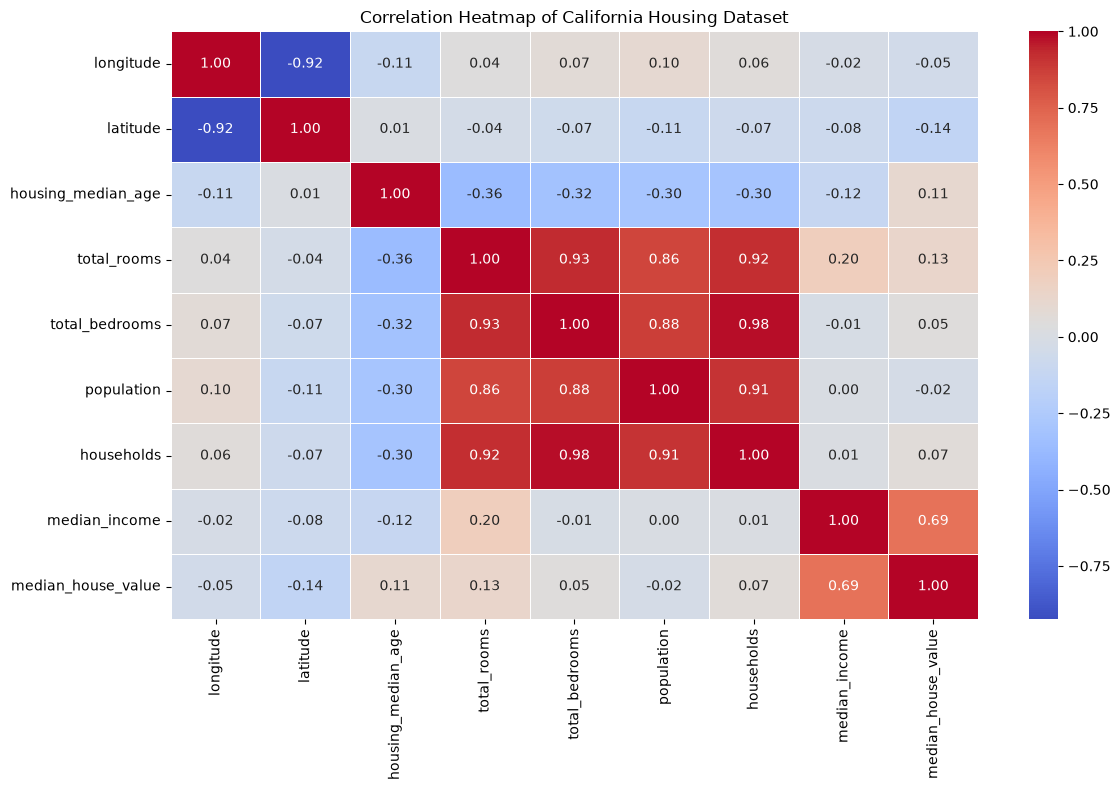

In [68]:
# Calculate correlations between numerical columns
correlation_matrix = df.corr(numeric_only=True)

# Display the heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of California Housing Dataset")
plt.tight_layout()

# Save the figure
plt.savefig("../results/correlation_heatmap.png", dpi=300)

plt.show()

In [69]:
# Create new features
df["rooms_per_household"] = (
    df["total_rooms"] / df["households"]
)

df["bedrooms_per_room"] = (
    df["total_bedrooms"] / df["total_rooms"]
)

df["population_per_household"] = (
    df["population"] / df["households"]
)

# Display the new features
df[
    [
        "rooms_per_household",
        "bedrooms_per_room",
        "population_per_household"
    ]
].head()

,rooms_per_household,bedrooms_per_room,population_per_household
0,6.984127,0.146591,2.555556
1,6.238137,0.155797,2.109842
2,8.288136,0.129516,2.802260
3,5.817352,0.184458,2.547945
4,6.281853,0.172096,2.181467


In [70]:
# Separate features and target
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (16512, 12)
Testing features: (4128, 12)
Training target: (16512,)
Testing target: (4128,)


In [71]:
# Identify numerical and categorical columns
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

Numerical features:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household']

Categorical features:
['ocean_proximity']

Number of numerical features: 11
Number of categorical features: 1


In [72]:
# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("interactions", PolynomialFeatures(
        degree=2,
        interaction_only=True,
        include_bias=False
    ))
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [73]:
# Fit the preprocessing pipeline on training data
X_train_prepared = preprocessor.fit_transform(X_train)

# Transform testing data using the same preprocessing
X_test_prepared = preprocessor.transform(X_test)

# Display the results
print("Training data shape:", X_train_prepared.shape)
print("Testing data shape:", X_test_prepared.shape)

print("\nPreprocessing completed successfully!")

Training data shape: (16512, 71)
Testing data shape: (4128, 71)

Preprocessing completed successfully!


In [74]:
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Training data shape:", X_train_prepared.shape)
print("Testing data shape:", X_test_prepared.shape)

print("\nPreprocessing completed successfully!")

Training data shape: (16512, 71)
Testing data shape: (4128, 71)

Preprocessing completed successfully!


In [75]:
# Create the OLS model
ols_model = LinearRegression()

# Train the model
ols_model.fit(X_train_prepared, y_train)

# Make predictions
ols_predictions = ols_model.predict(X_test_prepared)

print("OLS model trained successfully!")
print("Predictions for the first 5 houses:")
print(ols_predictions[:5])

OLS model trained successfully!
Predictions for the first 5 houses:
[ 58851.46023055 132824.22329934 319106.15607548 280553.70101574
 284270.11472684]


In [76]:
# Calculate evaluation metrics
ols_rmse = np.sqrt(mean_squared_error(y_test, ols_predictions))
ols_mae = mean_absolute_error(y_test, ols_predictions)
ols_r2 = r2_score(y_test, ols_predictions)

# Display results
print("OLS Regression Results")
print("----------------------")
print(f"RMSE: ${ols_rmse:,.2f}")
print(f"MAE:  ${ols_mae:,.2f}")
print(f"R²:   {ols_r2:.4f}")

OLS Regression Results
----------------------
RMSE: $65,527.62
MAE:  $45,617.65
R²:   0.6723


In [77]:
# Create the Ridge model
ridge_model = Ridge(alpha=1.0)

# Train the model
ridge_model.fit(X_train_prepared, y_train)

# Make predictions
ridge_predictions = ridge_model.predict(X_test_prepared)

print("Ridge model trained successfully!")
print("Predictions for the first 5 houses:")
print(ridge_predictions[:5])

Ridge model trained successfully!
Predictions for the first 5 houses:
[ 63754.73526544 134436.95446208 354137.73486736 276677.69996911
 284849.63622843]


In [78]:
# Calculate Ridge evaluation metrics
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_predictions))
ridge_mae = mean_absolute_error(y_test, ridge_predictions)
ridge_r2 = r2_score(y_test, ridge_predictions)

# Display results
print("Ridge Regression Results")
print("------------------------")
print(f"RMSE: ${ridge_rmse:,.2f}")
print(f"MAE:  ${ridge_mae:,.2f}")
print(f"R²:   {ridge_r2:.4f}")

Ridge Regression Results
------------------------
RMSE: $65,550.75
MAE:  $45,663.04
R²:   0.6721


In [79]:
# Create the Lasso model
lasso_model = Lasso(alpha=1.0, max_iter=10000)

# Train the model
lasso_model.fit(X_train_prepared, y_train)

# Make predictions
lasso_predictions = lasso_model.predict(X_test_prepared)

print("Lasso model trained successfully!")
print("Predictions for the first 5 houses:")
print(lasso_predictions[:5])

Lasso model trained successfully!
Predictions for the first 5 houses:
[ 55563.75312897 145276.91134646 379584.13062708 288296.92561735
 287587.52249372]


c:\Users\H\OneDrive\Datheon_Internship\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.906464e+13, tolerance: 2.207e+10
  model = cd_fast.enet_coordinate_descent(


In [80]:
# Improved numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("interactions", PolynomialFeatures(
        degree=2,
        interaction_only=True,
        include_bias=False
    )),
    ("scaler", StandardScaler())
])

# Rebuild the complete preprocessing pipeline
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Apply preprocessing again
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Improved preprocessing completed!")
print("Training shape:", X_train_prepared.shape)
print("Testing shape:", X_test_prepared.shape)

Improved preprocessing completed!
Training shape: (16512, 71)
Testing shape: (4128, 71)


In [ ]:
# Train the OLS model again using improved preprocessing
ols_model = LinearRegression()
ols_model.fit(X_train_prepared, y_train)

# Make predictions
ols_predictions = ols_model.predict(X_test_prepared)

print("OLS model retrained successfully!")

OLS model retrained successfully!


In [ ]:
# Train the Ridge model again
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_prepared, y_train)

# Make predictions
ridge_predictions = ridge_model.predict(X_test_prepared)

print("Ridge model retrained successfully!")

Ridge model retrained successfully!


In [ ]:
# Train the Lasso model again
lasso_model = Lasso(alpha=1.0, max_iter=50000)
lasso_model.fit(X_train_prepared, y_train)

# Make predictions
lasso_predictions = lasso_model.predict(X_test_prepared)

print("Lasso model retrained successfully!")

In [ ]:
# Train Lasso with stronger regularization
lasso_model = Lasso(alpha=10.0, max_iter=100000, tol=0.001)

lasso_model.fit(X_train_prepared, y_train)

# Make predictions
lasso_predictions = lasso_model.predict(X_test_prepared)

print("Lasso model trained with stronger regularization!")

Lasso model trained with stronger regularization!


c:\Users\H\OneDrive\Datheon_Internship\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.808001e+11, tolerance: 2.207e+11
  model = cd_fast.enet_coordinate_descent(


In [ ]:
lasso_model = Lasso(alpha=20.0, max_iter=100000, tol=0.001)

lasso_model.fit(X_train_prepared, y_train)

lasso_predictions = lasso_model.predict(X_test_prepared)

print("Lasso training completed!")


Lasso training completed!


In [ ]:
# Calculate evaluation metrics for each model

models = {
    "OLS": ols_predictions,
    "Ridge": ridge_predictions,
    "Lasso": lasso_predictions
}

results = []

for model_name, predictions in models.items():
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": model_name,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    })

results_df = pd.DataFrame(results)

print(results_df)

   Model           RMSE           MAE        R2
0    OLS  179952.036411  69788.740934 -1.471193
1  Ridge   67238.279663  47172.213357  0.654994
2  Lasso   67004.640387  47361.474731  0.657388


In [ ]:
ols_model = LinearRegression()

ols_model.fit(X_train_prepared, y_train)

ols_predictions = ols_model.predict(X_test_prepared)

print("OLS predictions recreated!")


OLS predictions recreated!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv("../data/housing.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (20640, 10)


In [ ]:
df["rooms_per_household"] = (
    df["total_rooms"] / df["households"]
)

df["bedrooms_per_room"] = (
    df["total_bedrooms"] / df["total_rooms"]
)

df["population_per_household"] = (
    df["population"] / df["households"]
)

print("Feature engineering completed!")
print("Dataset shape:", df.shape)

Feature engineering completed!
Dataset shape: (20640, 13)


In [ ]:
# Separate input features and target
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Data splitting completed!")
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Data splitting completed!
Training features: (16512, 12)
Testing features: (4128, 12)


In [ ]:
# Identify numerical and categorical features
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("interactions", PolynomialFeatures(
        degree=2,
        interaction_only=True,
        include_bias=False
    )),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created!")
print("Numerical features:", len(numerical_features))
print("Categorical features:", categorical_features)

Preprocessing pipeline created!
Numerical features: 11
Categorical features: ['ocean_proximity']


In [ ]:
# Fit preprocessing on training data
X_train_prepared = preprocessor.fit_transform(X_train)

# Apply the same transformations to testing data
X_test_prepared = preprocessor.transform(X_test)

print("Preprocessing completed!")
print("Training data shape:", X_train_prepared.shape)
print("Testing data shape:", X_test_prepared.shape)

Preprocessing completed!
Training data shape: (16512, 71)
Testing data shape: (4128, 71)


In [ ]:
# Initialize and train OLS
ols_model = LinearRegression()
ols_model.fit(X_train_prepared, y_train)

# Predict house prices
ols_predictions = ols_model.predict(X_test_prepared)

print("OLS model trained successfully!")

OLS model trained successfully!


In [ ]:
# Initialize and train Ridge Regression
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_prepared, y_train)

# Predict house prices
ridge_predictions = ridge_model.predict(X_test_prepared)

print("Ridge model trained successfully!")

Ridge model trained successfully!


In [ ]:
# Initialize and train Lasso Regression
lasso_model = Lasso(
    alpha=20.0,
    max_iter=100000,
    tol=0.001
)

lasso_model.fit(X_train_prepared, y_train)

# Predict house prices
lasso_predictions = lasso_model.predict(X_test_prepared)

print("Lasso model trained successfully!")

Lasso model trained successfully!


In [ ]:
# Store predictions from all three models
models = {
    "OLS": ols_predictions,
    "Ridge": ridge_predictions,
    "Lasso": lasso_predictions
}

# Calculate evaluation metrics
results = []

for model_name, predictions in models.items():
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": model_name,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    })

# Display results
results_df = pd.DataFrame(results)

print(results_df.round(2))

   Model       RMSE       MAE    R2
0    OLS  179952.04  69788.74 -1.47
1  Ridge   67238.28  47172.21  0.65
2  Lasso   67004.64  47361.47  0.66


In [ ]:
# Define possible alpha values
ridge_param_grid = {
    "alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

# Create GridSearchCV
ridge_grid_search = GridSearchCV(
    Ridge(),
    ridge_param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

# Perform hyperparameter tuning
ridge_grid_search.fit(X_train_prepared, y_train)

print("Best Ridge alpha:", ridge_grid_search.best_params_)
print("Best cross-validation RMSE:", -ridge_grid_search.best_score_)

Best Ridge alpha: {'alpha': 100}
Best cross-validation RMSE: 66321.31172026896


In [ ]:
# Create the optimized Ridge model
best_ridge_model = ridge_grid_search.best_estimator_

# Generate predictions
best_ridge_predictions = best_ridge_model.predict(X_test_prepared)

# Evaluate the optimized model
ridge_rmse = np.sqrt(
    mean_squared_error(y_test, best_ridge_predictions)
)

ridge_mae = mean_absolute_error(
    y_test, best_ridge_predictions
)

ridge_r2 = r2_score(
    y_test, best_ridge_predictions
)

print("Optimized Ridge Results")
print("-----------------------")
print("RMSE:", round(ridge_rmse, 2))
print("MAE:", round(ridge_mae, 2))
print("R2:", round(ridge_r2, 4))

Optimized Ridge Results
-----------------------
RMSE: 66506.9
MAE: 47496.77
R2: 0.6625


In [ ]:
# Define alpha values to test
ridge_param_grid = {
    "alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

# Create GridSearchCV
ridge_grid_search = GridSearchCV(
    Ridge(),
    ridge_param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

# Run the search
ridge_grid_search.fit(X_train_prepared, y_train)

print("Best Ridge alpha:", ridge_grid_search.best_params_)
print("Best cross-validation RMSE:", -ridge_grid_search.best_score_)

Best Ridge alpha: {'alpha': 100}
Best cross-validation RMSE: 66321.31172026896


In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge, Lasso

print("GridSearchCV, Ridge and Lasso imported successfully!")

GridSearchCV, Ridge and Lasso imported successfully!


In [ ]:
ridge_param_grid = {
    "alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

ridge_grid_search = GridSearchCV(
    Ridge(),
    ridge_param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

ridge_grid_search.fit(X_train_prepared, y_train)

print("Best Ridge alpha:", ridge_grid_search.best_params_)
print("Best cross-validation RMSE:", -ridge_grid_search.best_score_)

Best Ridge alpha: {'alpha': 100}
Best cross-validation RMSE: 66321.31172026896


In [ ]:
print("Hello! The notebook is working.")

Hello! The notebook is working.


In [ ]:
print("Kernel is working correctly!")
print("Python is ready for Task 2.")

Kernel is working correctly!
Python is ready for Task 2.


In [ ]:
print("Dataset:", "df" in globals())
print("Training data:", "X_train_prepared" in globals())
print("Target:", "y_train" in globals())
print("Ridge search:", "ridge_grid_search" in globals())

Dataset: True
Training data: True
Target: True
Ridge search: True


In [ ]:
# Load dataset
df = pd.read_csv("../data/housing.csv")

# Feature engineering
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]

# Separate features and target
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Identify feature types
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Dataset and features restored!")
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Dataset and features restored!
Training data: (16512, 12)
Testing data: (4128, 12)


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# Load dataset
df = pd.read_csv("../data/housing.csv")

# Feature engineering
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]

# Separate features and target
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Identify feature types
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Dataset and features restored!")
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Dataset and features restored!
Training data: (16512, 12)
Testing data: (4128, 12)


In [ ]:
# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("interactions", PolynomialFeatures(
        degree=2,
        interaction_only=True,
        include_bias=False
    )),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Prepare training and testing data
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Preprocessing completed!")
print("Training data shape:", X_train_prepared.shape)
print("Testing data shape:", X_test_prepared.shape)

Preprocessing completed!
Training data shape: (16512, 71)
Testing data shape: (4128, 71)


In [ ]:
# Create the models
models = {
    "OLS": LinearRegression(),
    "Ridge": Ridge(alpha=100),
    "Lasso": Lasso(alpha=20, max_iter=100000, tol=0.001)
}

# Train and evaluate each model
results = []

for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train_prepared, y_train)
    predictions = model.predict(X_test_prepared)

    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "RMSE": rmse,
        "MAE": mae,
        "R²": r2
    })

results_df = pd.DataFrame(results)

print("\nModel Comparison:")
display(results_df.round(2))

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify feature types
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Complete preprocessing
simple_preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

# Build the OLS pipeline
simple_pipeline = Pipeline([
    ("preprocessor", simple_preprocessor),
    ("model", LinearRegression())
])

# Train the OLS model
simple_pipeline.fit(X_train, y_train)


# Generate predictions
y_pred_simple = simple_pipeline.predict(X_test)

print("OLS model trained successfully!")

OLS model trained successfully!


In [ ]:
print("Preprocessor exists:", "simple_preprocessor" in globals())
print("OLS pipeline exists:", "simple_pipeline" in globals())
print("Training data exists:", "X_train" in globals())

Preprocessor exists: True
OLS pipeline exists: True
Training data exists: True


In [ ]:
print("OLS pipeline:", simple_pipeline)
print("OLS model fitted:",
      hasattr(simple_pipeline.named_steps["model"], "coef_"))

OLS pipeline: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['longitude', 'latitude',
                                                   'housing_median_age',
                                                   'total_rooms',
                                                   'total_bedrooms',
                                                   'population', 'households',
                                                   'median_income',
                                                   'rooms_per_household',
                                              

In [ ]:
# Define Ridge alpha values to test
ridge_param_grid = {
    "alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

# Create GridSearchCV
ridge_grid_search = GridSearchCV(
    Ridge(),
    ridge_param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

# Train and search for the best alpha
ridge_grid_search.fit(X_train_prepared, y_train)

print("Best Ridge alpha:", ridge_grid_search.best_params_["alpha"])
print("Best cross-validation RMSE:", -ridge_grid_search.best_score_)

Best Ridge alpha: 100
Best cross-validation RMSE: 66321.31172026896


In [ ]:
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
import numpy as np

# Build Lasso pipeline
lasso_pipeline = Pipeline([
    ("preprocessor", simple_preprocessor),
    ("model", Lasso(max_iter=20000, tol=1e-3))
])

# Alpha values
lasso_alphas = np.logspace(-2, 3, 11)

# Grid Search
lasso_grid = GridSearchCV(
    lasso_pipeline,
    param_grid={"model__alpha": lasso_alphas},
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    verbose=1
)

# Train and tune
lasso_grid.fit(X_train, y_train)

print("Best alpha:", lasso_grid.best_params_["model__alpha"])
print("Best CV RMSE:", -lasso_grid.best_score_)

Fitting 5 folds for each of 11 candidates, totalling 55 fits
Best alpha: 3.1622776601683795
Best CV RMSE: 67848.69538873275


In [ ]:
print("Training data shape:", X_train_prepared.shape)
print("Data type:", type(X_train_prepared))

Training data shape: (16512, 71)
Data type: <class 'numpy.ndarray'>


In [5]:
print("Dataset:", "df" in globals())
print("Test data:", "X_test_prepared" in globals())
print("Ridge predictions:", "ridge_predictions" in globals())
print("Best Ridge:", "best_ridge" in globals())

Dataset: False
Test data: False
Ridge predictions: False
Best Ridge: False


In [8]:
# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 2. Load dataset
df = pd.read_csv("../data/housing.csv")

# 3. Feature engineering
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]

# 4. Separate features and target
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

# 5. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 6. Identify feature types
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

# 7. Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("interactions", PolynomialFeatures(
        degree=2, interaction_only=True, include_bias=False
    )),
    ("scaler", StandardScaler())
])

# 8. Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# 9. Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

# 10. Prepare data
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Restoration successful!")
print("Dataset:", df.shape)
print("Training:", X_train_prepared.shape)
print("Testing:", X_test_prepared.shape)

Restoration successful!
Dataset: (20640, 13)
Training: (16512, 71)
Testing: (4128, 71)


In [9]:
# Create models using our previous settings
models = {
    "OLS": LinearRegression(),
    "Ridge": Ridge(alpha=100),
    "Lasso": Lasso(alpha=20, max_iter=100000, tol=0.001)
}

results = []
predictions = {}

# Train and evaluate
for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train_prepared, y_train)
    y_pred = model.predict(X_test_prepared)

    predictions[name] = y_pred

    results.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAE": mean_absolute_error(y_test, y_pred),
        "R²": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

print("\nModel comparison:")
display(results_df.round(2))

# Restore our best model references
best_ridge = models["Ridge"]
best_lasso = models["Lasso"]

ridge_predictions = predictions["Ridge"]
lasso_predictions = predictions["Lasso"]

Training OLS...
Training Ridge...
Training Lasso...

Model comparison:


,Model,RMSE,MAE,R²
0,OLS,179952.04,69788.74,-1.47
1,Ridge,66506.90,47496.77,0.66
2,Lasso,67004.64,47361.47,0.66


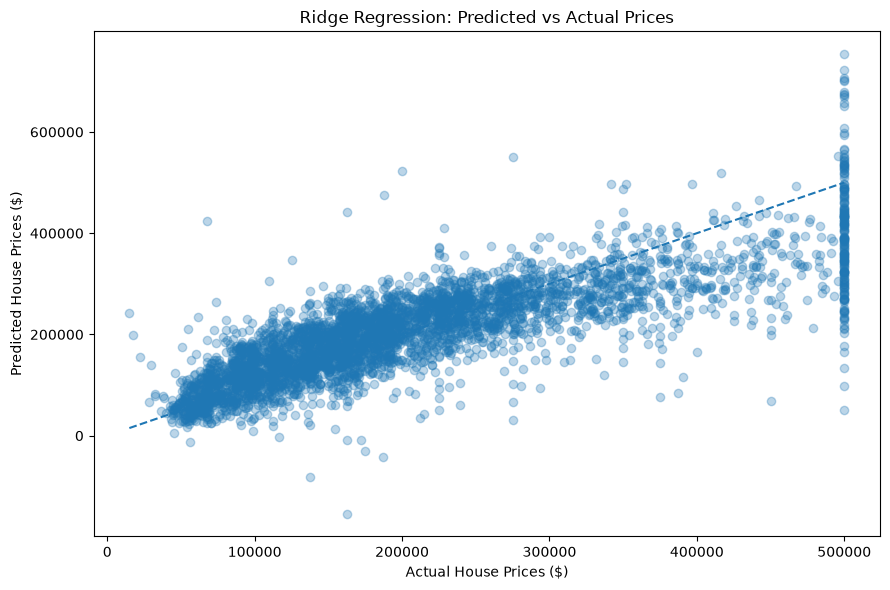

In [10]:
plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    ridge_predictions,
    alpha=0.3
)

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual House Prices ($)")
plt.ylabel("Predicted House Prices ($)")
plt.title("Ridge Regression: Predicted vs Actual Prices")

plt.tight_layout()

plt.savefig(
    "../results/ridge_predicted_vs_actual.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
from sklearn.linear_model import LinearRegression

# Create the model
ols_model = LinearRegression()

# Train the model
ols_model.fit(X_train_prepared, y_train)

# Make predictions
ols_predictions = ols_model.predict(X_test_prepared)

print("OLS model trained successfully!")
print("First 10 predictions:")
print(ols_predictions[:10])

OLS model trained successfully!
First 10 predictions:
[-210905.23304003  460080.9971362  1014618.10746749  652648.76028209
  365746.65732058 1084853.39651267  -28016.36235315 -136959.19629701
  290832.487142    488715.30797728]


In [12]:
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
import numpy as np

# Calculate evaluation metrics
ols_rmse = np.sqrt(mean_squared_error(y_test, ols_predictions))
ols_mae = mean_absolute_error(y_test, ols_predictions)
ols_r2 = r2_score(y_test, ols_predictions)

# Display results
print("OLS MODEL PERFORMANCE")
print("----------------------")
print("RMSE:", ols_rmse)
print("MAE:", ols_mae)
print("R2 Score:", ols_r2)

OLS MODEL PERFORMANCE
----------------------
RMSE: 179952.036411321
MAE: 69788.74093400098
R2 Score: -1.4711930356316816


In [13]:
print("TARGET VARIABLE")
print("----------------")
print(y_test.describe())

print("\nPREDICTION STATISTICS")
print("---------------------")
print("Minimum:", ols_predictions.min())
print("Maximum:", ols_predictions.max())
print("Mean:", ols_predictions.mean())
print("Standard deviation:", ols_predictions.std())

print("\nBASELINE COMPARISON")
print("-------------------")

baseline_predictions = np.full(
    len(y_test), y_train.mean()
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

print("OLS RMSE:", ols_rmse)
print("Baseline RMSE:", baseline_rmse)

TARGET VARIABLE
----------------
count      4128.000000
mean     205500.309593
std      114486.964288
min       14999.000000
25%      119275.000000
50%      178650.000000
75%      263000.000000
max      500001.000000
Name: median_house_value, dtype: float64

PREDICTION STATISTICS
---------------------
Minimum: -750092.594757552
Maximum: 4322611.184693883
Mean: 213208.25806510178
Standard deviation: 199568.626051034

BASELINE COMPARISON
-------------------
OLS RMSE: 179952.036411321
Baseline RMSE: 114485.63543099792


In [14]:
from sklearn.linear_model import Ridge

# Create Ridge model
ridge_model = Ridge(alpha=1.0)

# Train the model
ridge_model.fit(X_train_prepared, y_train)

# Make predictions
ridge_predictions = ridge_model.predict(X_test_prepared)

print("Ridge Regression trained successfully!")
print("First 10 predictions:")
print(ridge_predictions[:10])

Ridge Regression trained successfully!
First 10 predictions:
[ 21552.4954707  151607.5759341  365901.19657261 302475.04750465
 275789.10201665 234226.5738931  270611.77609248 183659.24103019
 242436.84196543 435688.98925144]


In [18]:
# Calculate evaluation metrics
ridge_rmse = np.sqrt(
    mean_squared_error(y_test, ridge_predictions)
)

ridge_mae = mean_absolute_error(
    y_test, ridge_predictions
)

ridge_r2 = r2_score(
    y_test, ridge_predictions
)

print("RIDGE REGRESSION PERFORMANCE")
print("-----------------------------")
print("RMSE:", ridge_rmse)
print("MAE:", ridge_mae)
print("R2 Score:", ridge_r2)

RIDGE REGRESSION PERFORMANCE
-----------------------------
RMSE: 67238.2796634143
MAE: 47172.21335679178
R2 Score: 0.6549942554450054


In [17]:
from sklearn.linear_model import Lasso

# Create Lasso model
lasso_model = Lasso(alpha=1.0, max_iter=10000)

# Train the model
lasso_model.fit(X_train_prepared, y_train)

# Make predictions
lasso_predictions = lasso_model.predict(X_test_prepared)

print("Lasso Regression trained successfully!")
print("First 10 predictions:")
print(lasso_predictions[:10])

Lasso Regression trained successfully!
First 10 predictions:
[ 34248.2631271  139397.09003809 345408.37969063 285545.31348448
 272959.06494393 194325.05106982 286495.77668295 200465.55405304
 241646.94023573 432417.41621453]


c:\Users\H\OneDrive\Datheon_Internship\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.032577e+13, tolerance: 2.207e+10
  model = cd_fast.enet_coordinate_descent(


In [20]:
lasso_rmse = np.sqrt(
    mean_squared_error(y_test, lasso_predictions)
)

lasso_mae = mean_absolute_error(
    y_test, lasso_predictions
)

lasso_r2 = r2_score(
    y_test, lasso_predictions
)

print("LASSO REGRESSION PERFORMANCE")
print("----------------------------")
print("RMSE:", lasso_rmse)
print("MAE:", lasso_mae)
print("R2 Score:", lasso_r2)

LASSO REGRESSION PERFORMANCE
----------------------------
RMSE: 66878.35162701584
MAE: 46837.96686902745
R2 Score: 0.6586780165112293


In [15]:
# Rebuild Lasso with more iterations
lasso_model = Lasso(
    alpha=1.0,
    max_iter=100000,
    tol=0.0001
)

# Train again
lasso_model.fit(X_train_prepared, y_train)

# Predict again
lasso_predictions = lasso_model.predict(X_test_prepared)

print("Lasso retrained successfully!")

Lasso retrained successfully!


c:\Users\H\OneDrive\Datheon_Internship\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.215543e+13, tolerance: 2.207e+10
  model = cd_fast.enet_coordinate_descent(


In [19]:
print("Prepared training data shape:", X_train_prepared.shape)

print("\nFeature value statistics:")
print("Minimum:", X_train_prepared.min())
print("Maximum:", X_train_prepared.max())

print("\nLasso iterations used:", lasso_model.n_iter_)


Prepared training data shape: (16512, 71)

Feature value statistics:
Minimum: -107.48936470453711
Maximum: 121.7793494522084

Lasso iterations used: 10000


In [ ]:
print("Training shape:", X_train_prepared.shape)
print("Testing shape:", X_test_prepared.shape)

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    PolynomialFeatures,
    OneHotEncoder
)
from sklearn.compose import ColumnTransformer

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("poly", PolynomialFeatures(
        degree=2,
        interaction_only=True,
        include_bias=False
    )),
    ("scaler", StandardScaler())
])

print("Numerical pipeline created!")

Numerical pipeline created!


In [23]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

print("Categorical pipeline created!")

Categorical pipeline created!


In [24]:
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessor created!")
print("Numerical features:", len(numerical_features))
print("Categorical features:", categorical_features)

Preprocessor created!
Numerical features: 11
Categorical features: ['ocean_proximity']


C:\Users\H\AppData\Local\Temp\ipykernel_22088\3302934331.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [25]:
print(df.shape)
print(df.head())

(20640, 13)
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  \
0       322.0       126.0         8.3252            452600.0        NEAR BAY   
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY   
2       496.0       177.0         7.2574            352100.0        NEAR BAY   
3       558.0       219.0         5.6431            341300.0        NEAR BAY   
4       565.0       259.0         3.8462            342200.0        NEAR BAY   

   rooms_per_household  bedrooms_per_room  population_pe

In [26]:
import pandas as pd

df = pd.read_csv("../data/housing.csv")

In [27]:
print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [28]:
# Create additional features
df["rooms_per_household"] = (
    df["total_rooms"] / df["households"]
)

df["bedrooms_per_room"] = (
    df["total_bedrooms"] / df["total_rooms"]
)

df["population_per_household"] = (
    df["population"] / df["households"]
)

print("Feature engineering completed!")
print("Dataset shape:", df.shape)

Feature engineering completed!
Dataset shape: (20640, 13)


In [29]:
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (20640, 12)
Target: (20640,)


In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (16512, 12)
Testing features: (4128, 12)
Training target: (16512,)
Testing target: (4128,)


In [31]:
# Identify numerical features
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical features
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nNumber of numerical features:", len(numeric_features))

print("\nCategorical features:", categorical_features)
print("Number of categorical features:", len(categorical_features))

Numerical features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household']

Number of numerical features: 11

Categorical features: ['ocean_proximity']
Number of categorical features: 1


C:\Users\H\AppData\Local\Temp\ipykernel_22088\2437099940.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [32]:
categorical_features = X_train.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

In [34]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("polynomial", PolynomialFeatures(
        degree=2,
        interaction_only=True,
        include_bias=False
    )),
    ("scaler", StandardScaler())
])

print("Numerical preprocessing pipeline created successfully!")

Numerical preprocessing pipeline created successfully!


In [35]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

print("Categorical preprocessing pipeline created successfully!")

Categorical preprocessing pipeline created successfully!


In [36]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Complete preprocessing system created successfully!")

Complete preprocessing system created successfully!


In [37]:
# Fit the preprocessor on training data and transform it
X_train_prepared = preprocessor.fit_transform(X_train)

# Transform testing data using the same fitted preprocessor
X_test_prepared = preprocessor.transform(X_test)

print("Preprocessing completed successfully!")

print("\nTraining data shape:", X_train_prepared.shape)
print("Testing data shape:", X_test_prepared.shape)

Preprocessing completed successfully!

Training data shape: (16512, 71)
Testing data shape: (4128, 71)


In [38]:
from sklearn.linear_model import LinearRegression

# Create the model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train_prepared, y_train)

# Make predictions
y_pred_linear = linear_model.predict(X_test_prepared)

print("Linear Regression trained successfully!")
print("\nFirst 10 predictions:")
print(y_pred_linear[:10])

Linear Regression trained successfully!

First 10 predictions:
[-210905.23304003  460080.9971362  1014618.10746749  652648.76028209
  365746.65732058 1084853.39651267  -28016.36235315 -136959.19629701
  290832.487142    488715.30797728]


In [39]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Calculate evaluation metrics
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
mae_linear = mean_absolute_error(y_test, y_pred_linear)
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Performance")
print("--------------------------------")
print("RMSE:", rmse_linear)
print("MAE:", mae_linear)
print("R² Score:", r2_linear)

Linear Regression Performance
--------------------------------
RMSE: 179952.036411321
MAE: 69788.74093400098
R² Score: -1.4711930356316816


In [40]:
# Predict the average training house price for every test sample
baseline_predictions = np.full(
    shape=len(y_test),
    fill_value=y_train.mean()
)

# Evaluate the baseline
baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_mae = mean_absolute_error(
    y_test, baseline_predictions
)

baseline_r2 = r2_score(
    y_test, baseline_predictions
)

print("Baseline Model Performance")
print("--------------------------------")
print("RMSE:", baseline_rmse)
print("MAE:", baseline_mae)
print("R² Score:", baseline_r2)

Baseline Model Performance
--------------------------------
RMSE: 114485.63543099792
MAE: 90606.8549000715
R² Score: -0.00021908714592466794


In [41]:
print("Actual house prices:")
print("Minimum:", y_test.min())
print("Maximum:", y_test.max())
print("Mean:", y_test.mean())

print("\nLinear Regression predictions:")
print("Minimum:", y_pred_linear.min())
print("Maximum:", y_pred_linear.max())
print("Mean:", y_pred_linear.mean())

print("\nNumber of negative predictions:")
print((y_pred_linear < 0).sum())

print("\nTraining target mean:")
print(y_train.mean())

Actual house prices:
Minimum: 14999.0
Maximum: 500001.0
Mean: 205500.30959302327

Linear Regression predictions:
Minimum: -750092.594757552
Maximum: 4322611.184693883
Mean: 213208.25806510178

Number of negative predictions:
90

Training target mean:
207194.6937378876


In [42]:
# Get the names of all prepared features
feature_names = preprocessor.get_feature_names_out()

# Match each feature with its Linear Regression coefficient
coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": linear_model.coef_
})

# Sort by absolute coefficient size
coefficient_df["Absolute_Coefficient"] = (
    coefficient_df["Coefficient"].abs()
)

coefficient_df = coefficient_df.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

print("Linear Regression intercept:")
print(linear_model.intercept_)

print("\nTop 15 largest coefficients:")
display(coefficient_df.head(15))

Linear Regression intercept:
230043.69205625282

Top 15 largest coefficients:


,Feature,Coefficient,Absolute_Coefficient
20,num__longitude population_per_household,3.014250e+06,3.014250e+06
10,num__population_per_household,2.534533e+06,2.534533e+06
17,num__longitude median_income,-2.162726e+06,2.162726e+06
14,num__longitude total_bedrooms,1.866219e+06,1.866219e+06
12,num__longitude housing_median_age,-1.586471e+06,1.586471e+06
16,num__longitude households,-1.577283e+06,1.577283e+06
7,num__median_income,-1.403584e+06,1.403584e+06
13,num__longitude total_rooms,-1.386441e+06,1.386441e+06
19,num__longitude bedrooms_per_room,-1.234552e+06,1.234552e+06
6,num__households,-1.163527e+06,1.163527e+06


In [43]:
import numpy as np
import pandas as pd

# Convert prepared training data into a NumPy array
X_array = np.asarray(X_train_prepared)

# Calculate correlations between features
correlation_matrix = np.corrcoef(X_array, rowvar=False)

# Get feature names
feature_names = preprocessor.get_feature_names_out()

# Extract only unique feature pairs (avoid duplicates and self-correlations)
upper_triangle = np.triu(
    np.ones(correlation_matrix.shape, dtype=bool),
    k=1
)

# Create a table of feature correlations
correlation_df = pd.DataFrame(
    correlation_matrix,
    index=feature_names,
    columns=feature_names
)

correlation_pairs = (
    correlation_df.where(upper_triangle)
    .stack()
    .reset_index()
)

correlation_pairs.columns = [
    "Feature_1",
    "Feature_2",
    "Correlation"
]

# Sort by absolute correlation
correlation_pairs["Absolute_Correlation"] = (
    correlation_pairs["Correlation"].abs()
)

correlation_pairs = correlation_pairs.sort_values(
    by="Absolute_Correlation",
    ascending=False
)

print("Top 15 strongest feature correlations:")
display(correlation_pairs.head(15))

Top 15 strongest feature correlations:


,Feature_1,Feature_2,Correlation,Absolute_Correlation
3177,num__total_rooms population_per_household,num__population rooms_per_household,1.000000,1.000000
327,num__total_bedrooms,num__total_rooms bedrooms_per_room,1.000000,1.000000
270,num__total_rooms,num__households rooms_per_household,1.000000,1.000000
414,num__population,num__households population_per_household,1.000000,1.000000
730,num__population_per_household,num__longitude population_per_household,-0.999976,0.999976
1124,num__longitude population,num__households population_per_household,-0.999663,0.999663
370,num__population,num__longitude population,-0.999663,0.999663
980,num__longitude total_rooms,num__households rooms_per_household,-0.999649,0.999649
226,num__total_rooms,num__longitude total_rooms,-0.999649,0.999649
298,num__total_bedrooms,num__longitude total_bedrooms,-0.999630,0.999630


In [44]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Numerical preprocessing without polynomial interactions
simple_numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
simple_categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
simple_preprocessor = ColumnTransformer([
    ("num", simple_numerical_pipeline, numeric_features),
    ("cat", simple_categorical_pipeline, categorical_features)
])

# Prepare the data
X_train_simple = simple_preprocessor.fit_transform(X_train)
X_test_simple = simple_preprocessor.transform(X_test)

print("Original prepared features:", X_train_prepared.shape[1])
print("Simplified prepared features:", X_train_simple.shape[1])

# Train Linear Regression
simple_linear_model = LinearRegression()
simple_linear_model.fit(X_train_simple, y_train)

# Predictions
y_pred_simple = simple_linear_model.predict(X_test_simple)

# Evaluation
print("\nSimplified Linear Regression Results")
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_simple)))
print("MAE:", mean_absolute_error(y_test, y_pred_simple))
print("R²:", r2_score(y_test, y_pred_simple))

Original prepared features: 71
Simplified prepared features: 16

Simplified Linear Regression Results
RMSE: 69127.03829924985
MAE: 49645.49244453642
R²: 0.635339233523819


In [45]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
simple_preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Simple preprocessor created successfully!")

Simple preprocessor created successfully!


C:\Users\H\AppData\Local\Temp\ipykernel_22088\2204689030.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [46]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
import numpy as np

# Build a complete pipeline
ridge_pipeline = Pipeline([
    ("preprocessor", simple_preprocessor),
    ("model", Ridge())
])

# Alpha values to test
alpha_values = np.logspace(-3, 3, 13)

# Grid Search
ridge_grid = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid={"model__alpha": alpha_values},
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    verbose=1
)

# Train and tune
ridge_grid.fit(X_train, y_train)

# Best model
best_ridge = ridge_grid.best_estimator_

# Test predictions
y_pred_best_ridge = best_ridge.predict(X_test)

# Results
print("Best alpha:", ridge_grid.best_params_["model__alpha"])
print("Best cross-validation RMSE:", -ridge_grid.best_score_)

print("\nTest Set Performance")
print("RMSE:", np.sqrt(mean_squared_error(
    y_test, y_pred_best_ridge
)))
print("MAE:", mean_absolute_error(
    y_test, y_pred_best_ridge
))
print("R²:", r2_score(
    y_test, y_pred_best_ridge
))

Fitting 5 folds for each of 13 candidates, totalling 65 fits
Best alpha: 1.0
Best cross-validation RMSE: 67847.58552226017

Test Set Performance
RMSE: 69134.96527371781
MAE: 49652.14287272517
R²: 0.6352555955611363


In [47]:
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
import numpy as np

# Complete Lasso pipeline
lasso_pipeline = Pipeline([
    ("preprocessor", simple_preprocessor),
    ("model", Lasso(max_iter=20000, tol=1e-3))
])

# Alpha values to test
lasso_alphas = np.logspace(-2, 3, 11)

# Grid Search
lasso_grid = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid={"model__alpha": lasso_alphas},
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    verbose=1
)

# Train and tune
lasso_grid.fit(X_train, y_train)

# Best model
best_lasso = lasso_grid.best_estimator_

# Predictions
y_pred_lasso = best_lasso.predict(X_test)

# Evaluation
print("Best alpha:", lasso_grid.best_params_["model__alpha"])
print("Best CV RMSE:", -lasso_grid.best_score_)

print("\nTest Set Performance")
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_lasso)))
print("MAE:", mean_absolute_error(y_test, y_pred_lasso))
print("R²:", r2_score(y_test, y_pred_lasso))

# Count coefficients reduced to zero
lasso_coefficients = best_lasso.named_steps["model"].coef_

print("\nNumber of coefficients:", len(lasso_coefficients))
print("Number of zero coefficients:", np.sum(lasso_coefficients == 0))

Fitting 5 folds for each of 11 candidates, totalling 55 fits
Best alpha: 3.1622776601683795
Best CV RMSE: 67848.69538873275

Test Set Performance
RMSE: 69130.57312298028
MAE: 49648.469154429775
R²: 0.6353019385804937

Number of coefficients: 16
Number of zero coefficients: 1


In [48]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Numerical preprocessing
rf_numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
rf_categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
rf_preprocessor = ColumnTransformer([
    ("num", rf_numerical_pipeline, numeric_features),
    ("cat", rf_categorical_pipeline, categorical_features)
])

# Create complete Random Forest pipeline
rf_pipeline = Pipeline([
    ("preprocessor", rf_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# Train
rf_pipeline.fit(X_train, y_train)

# Predict
y_pred_rf = rf_pipeline.predict(X_test)

# Evaluate
print("Random Forest Results")
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf)))
print("MAE:", mean_absolute_error(y_test, y_pred_rf))
print("R²:", r2_score(y_test, y_pred_rf))

Random Forest Results
RMSE: 49453.74812148636
MAE: 31746.073532284885
R²: 0.8133656557705747


In [49]:
from sklearn.model_selection import cross_val_score

# 5-fold cross-validation on training data
rf_cv_scores = cross_val_score(
    rf_pipeline,
    X_train,
    y_train,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=1
)

# Convert negative RMSE scores to positive values
rf_cv_rmse = -rf_cv_scores

print("Random Forest Cross-Validation Results")
print("Individual fold RMSE:", rf_cv_rmse)

print("\nMean CV RMSE:", rf_cv_rmse.mean())
print("Standard Deviation:", rf_cv_rmse.std())

print("\nTest RMSE:", 
      np.sqrt(mean_squared_error(y_test, y_pred_rf)))

Random Forest Cross-Validation Results
Individual fold RMSE: [49686.69968827 51006.01755269 50514.65398703 49366.4360283
 50058.26009264]

Mean CV RMSE: 50126.41346978644
Standard Deviation: 583.0939625709693

Test RMSE: 49453.74812148636


In [50]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

# Build a new Random Forest pipeline
rf_tuning_pipeline = Pipeline([
    ("preprocessor", rf_preprocessor),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

# Parameters to explore
param_distributions = {
    "model__n_estimators": [150, 200, 300],
    "model__max_depth": [None, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [0.7, 1.0]
}

# Randomized search
rf_random_search = RandomizedSearchCV(
    estimator=rf_tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=8,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Fit using training data only
rf_random_search.fit(X_train, y_train)

# Best model
best_rf = rf_random_search.best_estimator_

# Test predictions
y_pred_best_rf = best_rf.predict(X_test)

# Results
print("Best Parameters:")
print(rf_random_search.best_params_)

print("\nBest Cross-Validation RMSE:")
print(-rf_random_search.best_score_)

print("\nTest Set Results:")
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_best_rf)))
print("MAE:", mean_absolute_error(y_test, y_pred_best_rf))
print("R²:", r2_score(y_test, y_pred_best_rf))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Parameters:
{'model__n_estimators': 200, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 0.7, 'model__max_depth': 30}

Best Cross-Validation RMSE:
49913.98345793918

Test Set Results:
RMSE: 48737.003843377955
MAE: 31431.63052378618
R²: 0.8187363194948459


In [51]:
# Get the fitted preprocessing and Random Forest model
rf_preprocessor_fitted = best_rf.named_steps["preprocessor"]
rf_model_fitted = best_rf.named_steps["model"]

# Get transformed feature names
rf_feature_names = rf_preprocessor_fitted.get_feature_names_out()

# Create feature importance table
importance_df = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_model_fitted.feature_importances_
})

# Sort from most to least important
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Most Important Features:")
display(importance_df.head(15))

Top 15 Most Important Features:


,Feature,Importance
7,num__median_income,0.426397
12,cat__ocean_proximity_INLAND,0.156822
10,num__population_per_household,0.115175
0,num__longitude,0.062230
1,num__latitude,0.059253
9,num__bedrooms_per_room,0.048002
2,num__housing_median_age,0.042483
8,num__rooms_per_household,0.032356
3,num__total_rooms,0.013637
5,num__population,0.012829


In [52]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance
permutation_result = permutation_importance(
    best_rf,
    X_test,
    y_test,
    scoring="neg_root_mean_squared_error",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Create importance table using original feature names
permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": permutation_result.importances_mean,
    "Importance_Std": permutation_result.importances_std
})

# Sort by importance
permutation_df = permutation_df.sort_values(
    by="Importance_Mean",
    ascending=False
)

print("Permutation Feature Importance:")
display(permutation_df)

Permutation Feature Importance:


,Feature,Importance_Mean,Importance_Std
7,median_income,48734.983281,770.336033
8,ocean_proximity,21208.011702,770.492798
11,population_per_household,19779.898687,503.457400
0,longitude,18248.400323,427.188064
1,latitude,17659.482446,222.098984
2,housing_median_age,6934.550190,465.877286
10,bedrooms_per_room,3452.029943,232.568573
9,rooms_per_household,2575.759936,118.479189
3,total_rooms,234.792385,15.534301
4,total_bedrooms,233.573093,60.787362


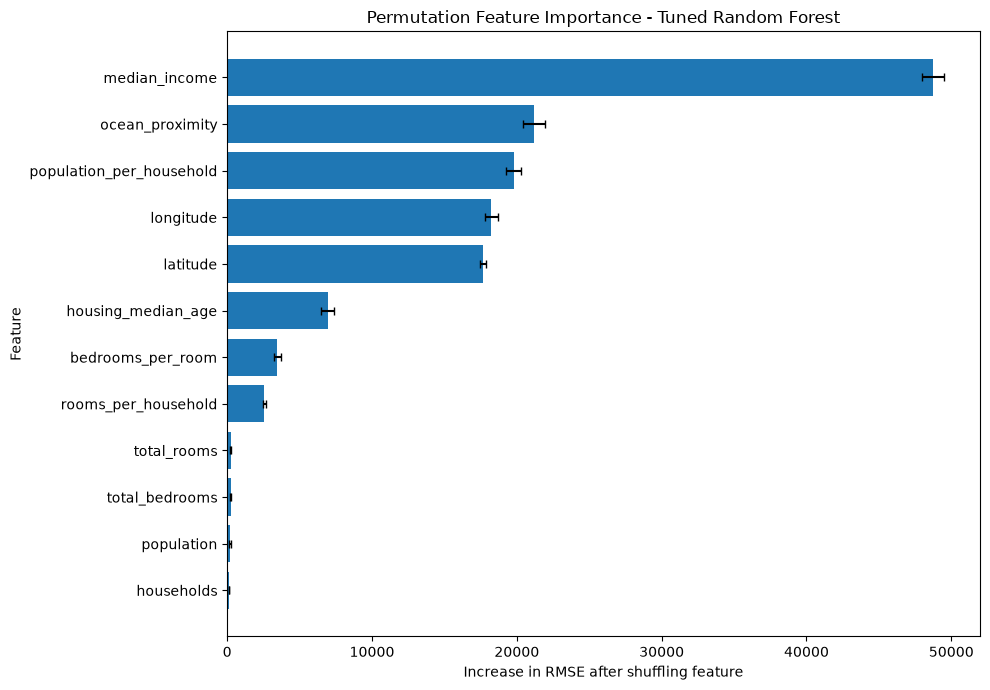

In [53]:
import matplotlib.pyplot as plt

# Sort features by importance for plotting
plot_df = permutation_df.sort_values(
    by="Importance_Mean",
    ascending=True
)

# Create figure
plt.figure(figsize=(10, 7))

plt.barh(
    plot_df["Feature"],
    plot_df["Importance_Mean"],
    xerr=plot_df["Importance_Std"],
    capsize=3
)

plt.xlabel("Increase in RMSE after shuffling feature")
plt.ylabel("Feature")
plt.title("Permutation Feature Importance - Tuned Random Forest")

plt.tight_layout()

# Save chart
plt.savefig(
    "../results/permutation_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

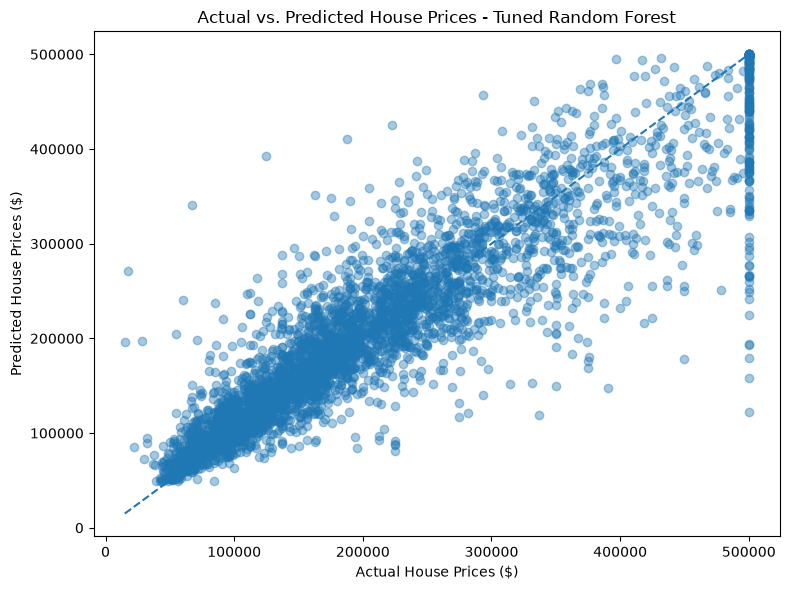

In [54]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_best_rf,
    alpha=0.4
)

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred_best_rf.min())
max_value = max(y_test.max(), y_pred_best_rf.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual House Prices ($)")
plt.ylabel("Predicted House Prices ($)")
plt.title("Actual vs. Predicted House Prices - Tuned Random Forest")

plt.tight_layout()

plt.savefig(
    "../results/actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

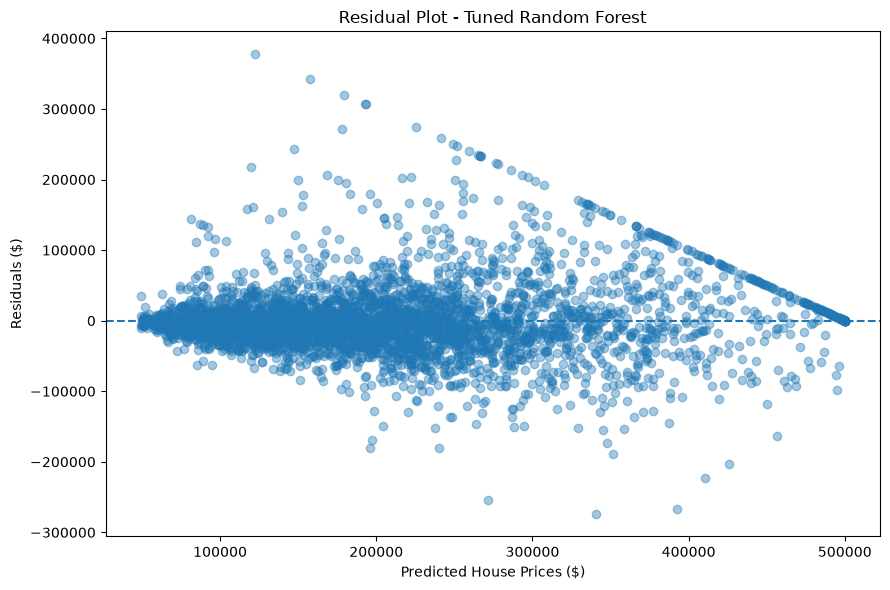

In [55]:
# Calculate residuals
residuals = y_test - y_pred_best_rf

plt.figure(figsize=(9, 6))

plt.scatter(
    y_pred_best_rf,
    residuals,
    alpha=0.4
)

# Reference line at zero
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted House Prices ($)")
plt.ylabel("Residuals ($)")
plt.title("Residual Plot - Tuned Random Forest")

plt.tight_layout()

plt.savefig(
    "../results/residual_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [56]:
# Create a results DataFrame
evaluation_df = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred_best_rf
})

# Group houses by actual price range
evaluation_df["Price_Range"] = pd.cut(
    evaluation_df["Actual"],
    bins=[0, 100000, 200000, 300000, 400000, 500001],
    labels=[
        "0–100k",
        "100k–200k",
        "200k–300k",
        "300k–400k",
        "400k–500001"
    ],
    include_lowest=True
)

# Calculate metrics for each group
range_results = evaluation_df.groupby(
    "Price_Range",
    observed=False
).apply(
    lambda group: pd.Series({
        "Number_of_Houses": len(group),
        "MAE": np.mean(
            np.abs(group["Actual"] - group["Predicted"])
        ),
        "RMSE": np.sqrt(
            np.mean(
                (group["Actual"] - group["Predicted"]) ** 2
            )
        )
    })
)

range_results

,Number_of_Houses,MAE,RMSE
Price_Range,,,
0–100k,739.0,19497.315172,31484.596099
100k–200k,1682.0,23647.091913,34654.361872
200k–300k,956.0,32623.935997,44162.727917
300k–400k,412.0,47699.718375,63731.922601
400k–500001,339.0,72938.287638,101823.103615


In [57]:
# Identify houses with the maximum recorded price
capped_houses = evaluation_df[
    evaluation_df["Actual"] == 500001
]

print("Number of capped houses:", len(capped_houses))

print(
    "Average predicted price:",
    capped_houses["Predicted"].mean()
)

print(
    "Average prediction error:",
    (capped_houses["Actual"] - capped_houses["Predicted"]).mean()
)

print(
    "MAE for capped houses:",
    np.abs(
        capped_houses["Actual"] - capped_houses["Predicted"]
    ).mean()
)

Number of capped houses: 179
Average predicted price: 424664.1215675589
Average prediction error: 75336.87843244111
MAE for capped houses: 75336.87843244111


In [58]:
# Separate capped and non-capped houses
capped_mask = evaluation_df["Actual"] == 500001

for label, subset in [
    ("Capped houses", evaluation_df[capped_mask]),
    ("Non-capped houses", evaluation_df[~capped_mask])
]:
    mae = np.mean(
        np.abs(subset["Actual"] - subset["Predicted"])
    )

    rmse = np.sqrt(
        np.mean(
            (subset["Actual"] - subset["Predicted"]) ** 2
        )
    )

    print(f"\n{label}")
    print("Number of houses:", len(subset))
    print(f"MAE: ${mae:,.2f}")
    print(f"RMSE: ${rmse:,.2f}")


Capped houses
Number of houses: 179
MAE: $75,336.88
RMSE: $111,903.42

Non-capped houses
Number of houses: 3949
MAE: $29,441.50
RMSE: $43,764.71


In [59]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Build Extra Trees pipeline
extra_trees_pipeline = Pipeline([
    ("preprocessor", rf_preprocessor),
    ("model", ExtraTreesRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# Train model
extra_trees_pipeline.fit(X_train, y_train)

# Make predictions
y_pred_extra = extra_trees_pipeline.predict(X_test)

# Evaluate
extra_rmse = np.sqrt(mean_squared_error(y_test, y_pred_extra))
extra_mae = mean_absolute_error(y_test, y_pred_extra)
extra_r2 = r2_score(y_test, y_pred_extra)

print("Extra Trees Performance")
print("-----------------------")
print(f"RMSE: ${extra_rmse:,.2f}")
print(f"MAE:  ${extra_mae:,.2f}")
print(f"R²:   {extra_r2:.4f}")

Extra Trees Performance
-----------------------
RMSE: $50,313.56
MAE:  $32,898.45
R²:   0.8068


In [60]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Build HistGradientBoosting pipeline
hist_pipeline = Pipeline([
    ("preprocessor", rf_preprocessor),
    ("model", HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.1,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    ))
])

# Train
hist_pipeline.fit(X_train, y_train)

# Predict
y_pred_hist = hist_pipeline.predict(X_test)

# Evaluate
hist_rmse = np.sqrt(mean_squared_error(y_test, y_pred_hist))
hist_mae = mean_absolute_error(y_test, y_pred_hist)
hist_r2 = r2_score(y_test, y_pred_hist)

print("HistGradientBoosting Performance")
print("--------------------------------")
print(f"RMSE: ${hist_rmse:,.2f}")
print(f"MAE:  ${hist_mae:,.2f}")
print(f"R²:   {hist_r2:.4f}")

HistGradientBoosting Performance
--------------------------------
RMSE: $45,066.20
MAE:  $29,688.57
R²:   0.8450


In [61]:
from sklearn.model_selection import RandomizedSearchCV

# Pipeline for tuning
hist_tuning_pipeline = Pipeline([
    ("preprocessor", rf_preprocessor),
    ("model", HistGradientBoostingRegressor(
        random_state=42
    ))
])

# Hyperparameter search space
hist_param_distributions = {
    "model__max_iter": [200, 300, 400],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__min_samples_leaf": [10, 20, 30],
    "model__l2_regularization": [0, 1, 5, 10]
}

# Randomized search
hist_random_search = RandomizedSearchCV(
    estimator=hist_tuning_pipeline,
    param_distributions=hist_param_distributions,
    n_iter=12,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Train and tune
hist_random_search.fit(X_train, y_train)

# Best model
best_hist = hist_random_search.best_estimator_

print("Best parameters:")
print(hist_random_search.best_params_)

print(
    "\nBest cross-validation RMSE:",
    f"${-hist_random_search.best_score_:,.2f}"
)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters:
{'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 63, 'model__max_iter': 200, 'model__learning_rate': 0.05, 'model__l2_regularization': 5}

Best cross-validation RMSE: $46,407.59


In [62]:
# Predict using the tuned model
y_pred_best_hist = best_hist.predict(X_test)

# Calculate test metrics
best_hist_rmse = np.sqrt(
    mean_squared_error(y_test, y_pred_best_hist)
)

best_hist_mae = mean_absolute_error(
    y_test, y_pred_best_hist
)

best_hist_r2 = r2_score(
    y_test, y_pred_best_hist
)

print("Tuned HistGradientBoosting Performance")
print("---------------------------------------")
print(f"RMSE: ${best_hist_rmse:,.2f}")
print(f"MAE:  ${best_hist_mae:,.2f}")
print(f"R²:   {best_hist_r2:.4f}")

Tuned HistGradientBoosting Performance
---------------------------------------
RMSE: $45,070.13
MAE:  $29,411.32
R²:   0.8450


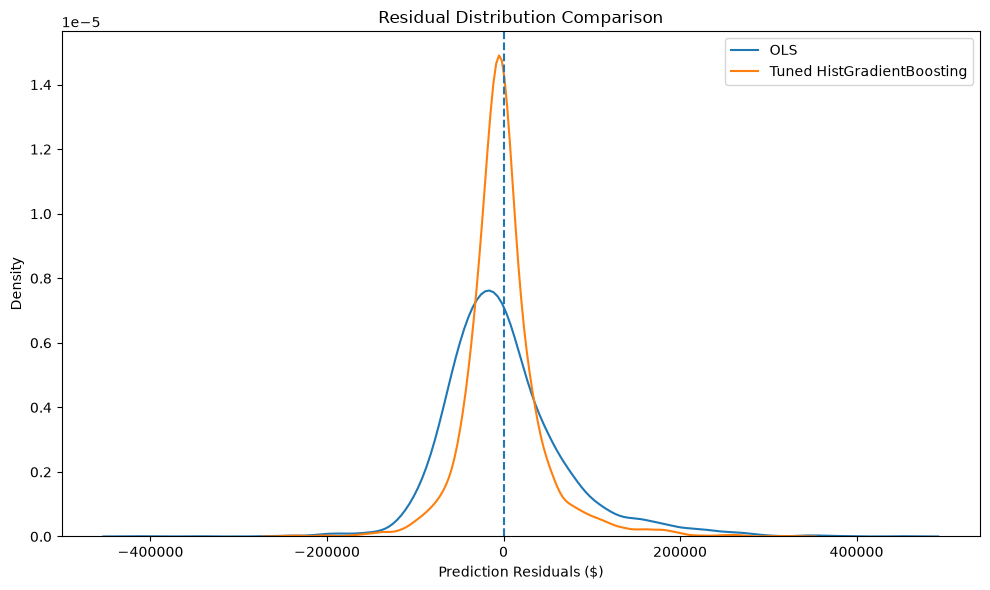

In [63]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate residuals
ols_residuals = y_test - y_pred_simple
best_residuals = y_test - y_pred_best_hist

plt.figure(figsize=(10, 6))

sns.kdeplot(
    ols_residuals,
    label="OLS",
    fill=False
)

sns.kdeplot(
    best_residuals,
    label="Tuned HistGradientBoosting",
    fill=False
)

plt.axvline(0, linestyle="--")

plt.xlabel("Prediction Residuals ($)")
plt.ylabel("Density")
plt.title("Residual Distribution Comparison")

plt.legend()
plt.tight_layout()

plt.savefig(
    "../results/residual_distribution_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [66]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

# Create and train the OLS pipeline
simple_pipeline = Pipeline([
    ("preprocessor", simple_preprocessor),
    ("model", LinearRegression())
])

simple_pipeline.fit(X_train, y_train)

print("OLS model trained successfully!")

OLS model trained successfully!


In [67]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

# OLS predictions
y_pred_ols = simple_pipeline.predict(X_test)

# Ridge predictions
y_pred_ridge = ridge_grid.best_estimator_.predict(X_test)

# Lasso predictions
y_pred_lasso = lasso_grid.best_estimator_.predict(X_test)

# Evaluation function
def evaluate_model(name, y_true, predictions):
    return {
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_true, predictions)),
        "MAE": mean_absolute_error(y_true, predictions),
        "R2": r2_score(y_true, predictions)
    }

linear_comparison = pd.DataFrame([
    evaluate_model("OLS", y_test, y_pred_ols),
    evaluate_model("Ridge", y_test, y_pred_ridge),
    evaluate_model("Lasso", y_test, y_pred_lasso)
])

linear_comparison = linear_comparison.sort_values(
    by="RMSE"
).reset_index(drop=True)

display(linear_comparison.round(2))

,Model,RMSE,MAE,R2
0,OLS,69127.04,49645.49,0.64
1,Lasso,69130.57,49648.47,0.64
2,Ridge,69134.97,49652.14,0.64


In [68]:
# Calculate metrics for OLS
simple_rmse = np.sqrt(mean_squared_error(y_test, y_pred_simple))
simple_mae = mean_absolute_error(y_test, y_pred_simple)
simple_r2 = r2_score(y_test, y_pred_simple)

# Calculate metrics for Ridge
ridge_rmse = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
ridge_mae = mean_absolute_error(y_test, y_pred_ridge)
ridge_r2 = r2_score(y_test, y_pred_ridge)

# Calculate metrics for Lasso
lasso_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lasso))
lasso_mae = mean_absolute_error(y_test, y_pred_lasso)
lasso_r2 = r2_score(y_test, y_pred_lasso)

print("All three models evaluated successfully!")

All three models evaluated successfully!


In [69]:
linear_comparison = pd.DataFrame({
    "Model": ["OLS", "Ridge", "Lasso"],
    "RMSE": [simple_rmse, ridge_rmse, lasso_rmse],
    "MAE": [simple_mae, ridge_mae, lasso_mae],
    "R2": [simple_r2, ridge_r2, lasso_r2]
})

linear_comparison = linear_comparison.sort_values(
    by="RMSE"
).reset_index(drop=True)

linear_comparison

,Model,RMSE,MAE,R2
0,OLS,69127.038299,49645.492445,0.635339
1,Lasso,69130.573123,49648.469154,0.635302
2,Ridge,69134.965274,49652.142873,0.635256


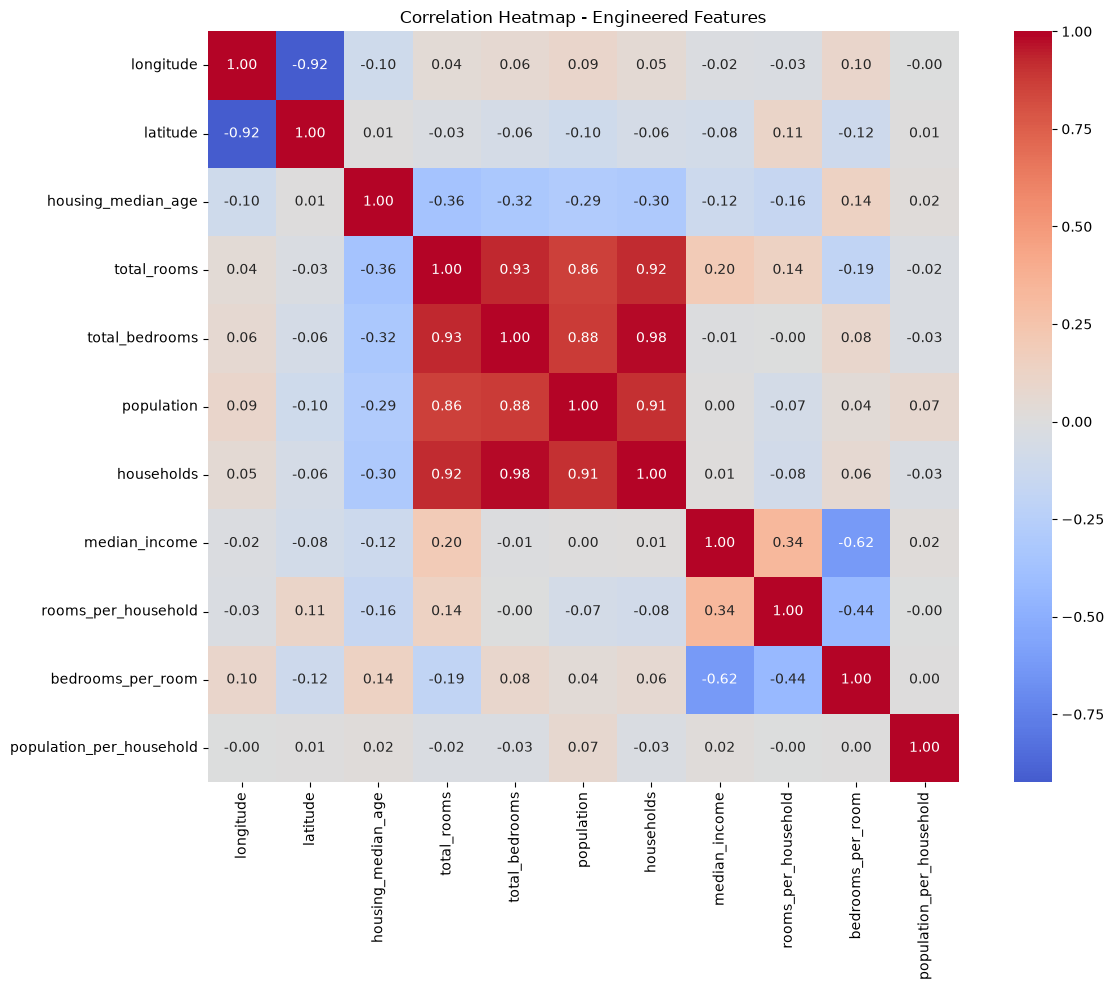

In [70]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select numerical features
correlation_features = X_train.select_dtypes(
    include=["number"]
)

# Calculate correlation matrix
correlation_matrix = correlation_features.corr()

# Plot heatmap
plt.figure(figsize=(13, 10))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    square=True
)

plt.title("Correlation Heatmap - Engineered Features")
plt.tight_layout()

plt.savefig(
    "../results/engineered_feature_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [71]:
# Collect predictions from all trained models
model_predictions = {
    "OLS": y_pred_simple,
    "Ridge": y_pred_ridge,
    "Lasso": y_pred_lasso,
    "Random Forest": y_pred_best_rf,
    "Extra Trees": y_pred_extra,
    "HistGradientBoosting": y_pred_hist,
    "Tuned HistGradientBoosting": y_pred_best_hist
}

# Calculate evaluation metrics
final_results = []

for model_name, predictions in model_predictions.items():
    final_results.append({
        "Model": model_name,
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "MAE": mean_absolute_error(y_test, predictions),
        "R2": r2_score(y_test, predictions)
    })

final_comparison = pd.DataFrame(final_results)

final_comparison = final_comparison.sort_values(
    by="RMSE"
).reset_index(drop=True)

final_comparison

,Model,RMSE,MAE,R2
0,HistGradientBoosting,45066.201352,29688.573832,0.845013
1,Tuned HistGradientBoosting,45070.133168,29411.319838,0.844986
2,Random Forest,48737.003843,31431.630524,0.818736
3,Extra Trees,50313.562091,32898.448988,0.806820
4,OLS,69127.038299,49645.492445,0.635339
5,Lasso,69130.573123,49648.469154,0.635302
6,Ridge,69134.965274,49652.142873,0.635256


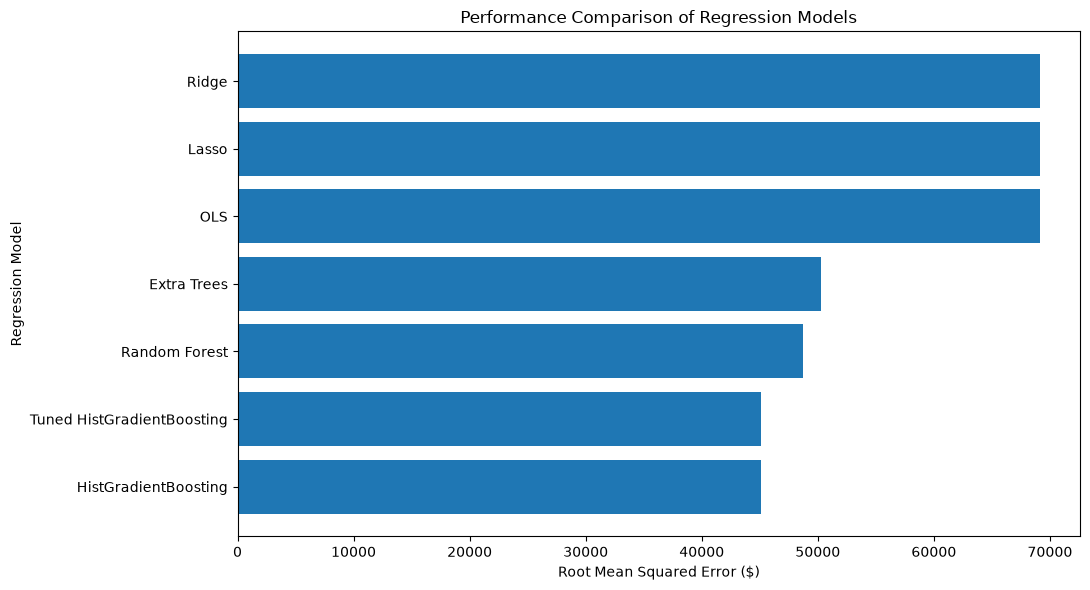

In [72]:
import matplotlib.pyplot as plt

plot_results = final_comparison.sort_values(
    by="RMSE",
    ascending=True
)

plt.figure(figsize=(11, 6))

plt.barh(
    plot_results["Model"],
    plot_results["RMSE"]
)

plt.xlabel("Root Mean Squared Error ($)")
plt.ylabel("Regression Model")
plt.title("Performance Comparison of Regression Models")

plt.tight_layout()

plt.savefig(
    "../results/final_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [74]:
# Calculate residuals for each linear model
ols_residuals = y_test - y_pred_ols
ridge_residuals = y_test - y_pred_ridge
lasso_residuals = y_test - y_pred_lasso

print("Residuals calculated successfully!")
print("OLS:", len(ols_residuals))
print("Ridge:", len(ridge_residuals))
print("Lasso:", len(lasso_residuals))

Residuals calculated successfully!
OLS: 4128
Ridge: 4128
Lasso: 4128


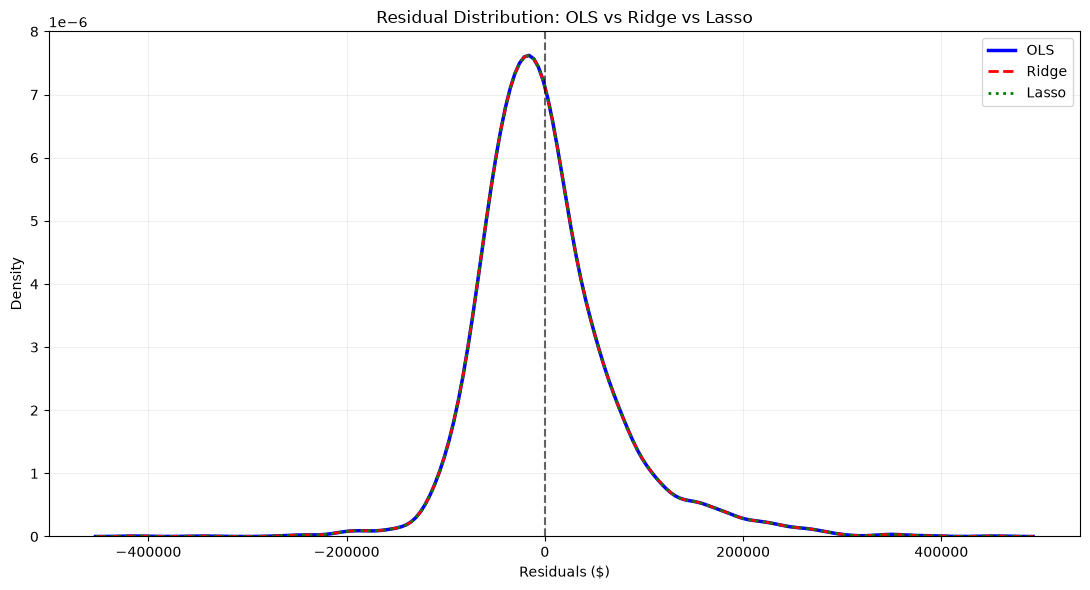

In [75]:
plt.figure(figsize=(11, 6))

sns.kdeplot(
    ols_residuals,
    label="OLS",
    color="blue",
    linestyle="-",
    linewidth=2.5
)

sns.kdeplot(
    ridge_residuals,
    label="Ridge",
    color="red",
    linestyle="--",
    linewidth=2
)

sns.kdeplot(
    lasso_residuals,
    label="Lasso",
    color="green",
    linestyle=":",
    linewidth=2
)

plt.axvline(0, color="black", linestyle="--", alpha=0.6)

plt.xlabel("Residuals ($)")
plt.ylabel("Density")
plt.title("Residual Distribution: OLS vs Ridge vs Lasso")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "../results/linear_models_residual_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [76]:
print("OLS residuals:")
print(ols_residuals.describe())

print("\nRidge residuals:")
print(ridge_residuals.describe())

print("\nLasso residuals:")
print(lasso_residuals.describe())

print("\nMaximum absolute differences:")
print("OLS vs Ridge:", np.max(np.abs(ols_residuals - ridge_residuals)))
print("OLS vs Lasso:", np.max(np.abs(ols_residuals - lasso_residuals)))

OLS residuals:
count      4128.000000
mean        783.758165
std       69130.968984
min     -414151.567348
25%      -41836.771517
50%       -8746.888401
75%       30149.507020
max      453363.640424
Name: median_house_value, dtype: float64

Ridge residuals:
count      4128.000000
mean        784.924881
std       69138.884189
min     -413641.925704
25%      -41838.271003
50%       -8725.167316
75%       30172.205432
max      453376.141026
Name: median_house_value, dtype: float64

Lasso residuals:
count      4128.000000
mean        784.350989
std       69134.497738
min     -413673.990272
25%      -41836.266694
50%       -8736.751249
75%       30184.916609
max      453376.102879
Name: median_house_value, dtype: float64

Maximum absolute differences:
OLS vs Ridge: 23349.05650055583
OLS vs Lasso: 13061.425097644562


In [77]:
# Save final model comparison as CSV
final_comparison.to_csv(
    "../results/final_model_comparison.csv",
    index=False
)

print("Final model comparison saved successfully!")

Final model comparison saved successfully!
